# Practice Session 01: Management of networks data. NetworkX and Pandas

*Introduction to Network Science* (2026/27), UPF

Author: <font color="blue">Pol Rovira Almirall</font>

E-mail: <font color="blue">pol.rovira02@estudiant.upf.edu</font>

Date: <font color="blue">19/10/2026</font>

In the first past of this session, we will learn how to use the **NetworkX** Python package to do basic network visualization and analysis.

In the second part, we will use the **Pandas** package to analyze a small dataset in the context of gastronomy: the *Flavors network*, a bi-partite network connecting culinary ingredients to flavour compounds [*].

[*] Ahn, Y. Y., Ahnert, S. E., Bagrow, J. P., & Barabasi, A. L. (2011). [Flavor network and the principles of food pairing](https://doi.org/10.1038/srep00196). Scientific reports, 1(1), 1-7.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

# 1. Introduction to NetworkX

In this course, we will rely heavily on the [NetworkX](https://networkx.org/) Python package. This is the *de facto* standard tool for basic network analysis and visualization in Python, and it will be a very useful addition to your data analysis and modelling toolbox.

Since from now on we will analyze networks programmatically with `networkx`, you will find it necessary and useful to consult the **[NetworkX documentation](https://networkx.org/documentation/stable/index.html)**, especially the [Reference](https://networkx.org/documentation/stable/reference/index.html) (e.g. [Introduction](https://networkx.org/documentation/stable/reference/introduction.html), [Algorithms](https://networkx.org/documentation/stable/reference/algorithms/index.html), [Drawing](https://networkx.org/documentation/stable/reference/drawing.html)) and the [Gallery](https://networkx.org/documentation/stable/auto_examples/index.html).

(If you wish, you may follow or skim through the [Tutorial](https://networkx.org/documentation/stable/tutorial.html) to get an overview of the syntax and functionality of `networkx`.)

---

:warning: **Why NetworkX?** There are many tool for network visualization and analysis. Software applications like [Cytoscape](https://cytoscape.org/) and [Gephi](https://gephi.org/) allow for performing basic analysis in a fast, no-coding way, and provide many conveniences for visualization, but they usually have a fixed functionality and are difficult to extend. On the other end of the spectrum, software packages like [graph-tool](https://graph-tool.skewed.de/), [igraph](https://igraph.org/), and [graphviz](https://graphviz.org/#download) provide efficient algorithms for analysis and visualization of large networks, but may be less intuitive and take more time to learn and get used to. [NetworkX](https://networkx.org/) has become popular partly because it sits somewhere in the middle: with easy installation, fairly intuitive API, and decent flexibility. You might not need it for the most basic analysis, and if you have very large networks it might be too slow, but for a vast range of applications it's a versatile, powerful tool for network analysis, and thus you will find it useful as a data science tool going forward.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [1]:
# LEAVE THIS CODE AS-IS

# Import networkx
import networkx as nx

# Import matplotlib for visualization
import matplotlib.pyplot as plt

First, let's import the Karate Club network. It is provided as a GML file in the GitHub `practicum/data/karate-club` folder.

The ["Zachary's Karate Club"](https://en.wikipedia.org/wiki/Zachary's_karate_club) graph is a classic social network, which nowadays serves as the "Hello World" of network analysis. It represents the members of a karate club (nodes) and their interactions (edges) before the club split into two, due to disagreements between the instructor (node "1") and the president (node "34").

There are many ways to read in data with NetworkX, from both graph-specific formats (GML, GraphML, adjacency/edge lists) and general data formats (CSV, JSON). See [Reading and writing graphs](https://networkx.org/documentation/stable/reference/readwrite/index.html) in the documentation.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [2]:
# EDIT THIS CODE if needed to point to your file (as you will include it in the submission zip)

karate_club = nx.read_gml('data/karate-club/karate.gml', label=None)

The code below generates a `Graph`, which is the most important object in `networkx`. We will be mostly concerned with creating and manipulating different [`Graph` classes](https://networkx.org/documentation/stable/reference/classes/index.html) that hold [nodes](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.nodes.html), [edges](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.edges.html), and node/edge [attributes](https://networkx.org/documentation/stable/reference/functions.html#attributes).

At first glance, a `Graph` object is kind of like a Python dictionary. It contains all of the data about nodes, edges, and their attributies (if any).

For example, we can access the basic elements of the graph as follows:

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [5]:
# LEAVE THIS CODE AS-IS

# Get the list-like iterable of nodes
kc_nodes = karate_club.nodes()
print(f"Karate club nodes: {kc_nodes}")

# Get the list-like iterable of edges
kc_edges = karate_club.edges()
print(f"Karate club edges: {kc_edges}")

# We can also use other utility functions to get basic information about the graph
print(f"Number of nodes: {karate_club.number_of_nodes()}")
print(f"Number of edges: {karate_club.number_of_edges()}")

Karate club nodes: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34]
Karate club edges: [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 11), (1, 12), (1, 13), (1, 14), (1, 18), (1, 20), (1, 22), (1, 32), (2, 3), (2, 4), (2, 8), (2, 14), (2, 18), (2, 20), (2, 22), (2, 31), (3, 4), (3, 8), (3, 9), (3, 10), (3, 14), (3, 28), (3, 29), (3, 33), (4, 8), (4, 13), (4, 14), (5, 7), (5, 11), (6, 7), (6, 11), (6, 17), (7, 17), (9, 31), (9, 33), (9, 34), (10, 34), (14, 34), (15, 33), (15, 34), (16, 33), (16, 34), (19, 33), (19, 34), (20, 34), (21, 33), (21, 34), (23, 33), (23, 34), (24, 26), (24, 28), (24, 30), (24, 33), (24, 34), (25, 26), (25, 28), (25, 32), (26, 32), (27, 30), (27, 34), (28, 34), (29, 32), (29, 34), (30, 33), (30, 34), (31, 33), (31, 34), (32, 33), (32, 34), (33, 34)]
Number of nodes: 34
Number of edges: 78


Each node has a unique label, and in this case we have created the `Graph` with nodes represented with **integer labels**. Therefore, edges are tuples of integers. (You can also use other objects as node labels, for example strings as we do in Section 2.)

If we have added any attributes (arbitrary data) to nodes or edges, we can access it by passing the `data=True` argument to the functions above, as shown below for nodes. What we get is a `DataView` object, which is a "dict of dicts", with node labels as keys and node data dictionaries (if any) as values.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [6]:
# LEAVE THIS CODE AS-IS

karate_club.nodes(data=True)

# You can see the two key nodes (sensei and president) have attributes

NodeDataView({1: {'label': '1 (sensei)'}, 2: {}, 3: {}, 4: {}, 5: {}, 6: {}, 7: {}, 8: {}, 9: {}, 10: {}, 11: {}, 12: {}, 13: {}, 14: {}, 15: {}, 16: {}, 17: {}, 18: {}, 19: {}, 20: {}, 21: {}, 22: {}, 23: {}, 24: {}, 25: {}, 26: {}, 27: {}, 28: {}, 29: {}, 30: {}, 31: {}, 32: {}, 33: {}, 34: {'label': '34 (president)'}})

Let's do our first visualization. 

---

***Quick NetworkX visualization explainer***

With the `networkx` [drawing](https://networkx.org/documentation/stable/reference/drawing.html) utilities, we can plot networks (as `matplotlib` Figures) and customize node and edge styles any way we like.

As we saw with Cytoscape, the two basic elements of a network visualization are the **layout** and the element (node, edge) **styles**.

The basic visualization function in `networkx` is [`nx.draw`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw.html), which has the following signature:

```python
    nx.draw(g, pos=node_layout, **style_keywords)
```

Very briefly:
* We specify the graph we want to draw as `g`.
* The `pos` parameter takes as argument a dictionary mapping nodes in `g` to positions (coordinates in 2D space). 
    * There are [many functions](https://networkx.org/documentation/stable/reference/drawing.html#module-networkx.drawing.layout) in `networkx` for generating different layouts (i.e. node positions). Below we give an example using [`nx.spring_layout`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.layout.spring_layout.html).
* In `style_keywords` we pass the function a set of keyword arguments (either as a dictionary, or one-by-one) that affect the appearance of nodes, edges, and labels. 
    * For the basic set of parameters we can pass, and their formats, see the documentation entry of [`nx.draw_networkx`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx.html).

There are basically two approaches for plotting with `networkx`:

* Using the basic `nx.draw()` function, and passing the styles as arguments to that function; or
* Using separate calls to `draw_networkx_nodes()`, `draw_networkx_edges()` and `draw_networkx_labels()` to draw the respective elements separately (see next section).

Note that under the hood `nx.draw()` uses the `draw_networkx_nodes()`, etc., functions, and it is those lower-level functions that define the names and permitted values of the styling parameters. You should check their documentation for reference.

For more information, see the NetworkX [Drawing](https://networkx.org/documentation/stable/reference/drawing.html) documentation.

*Tip: In the future, if you want to step up your network visualization game, check out the [`netgraph`](https://github.com/paulbrodersen/netgraph) package!*

---

Below, we use `nx.spring_layout`, which is a random layout, meaning it will produce a different output every time you run the cell (try it!). We draw with the default node/edge styles, but ask it additionally to draw the labels.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

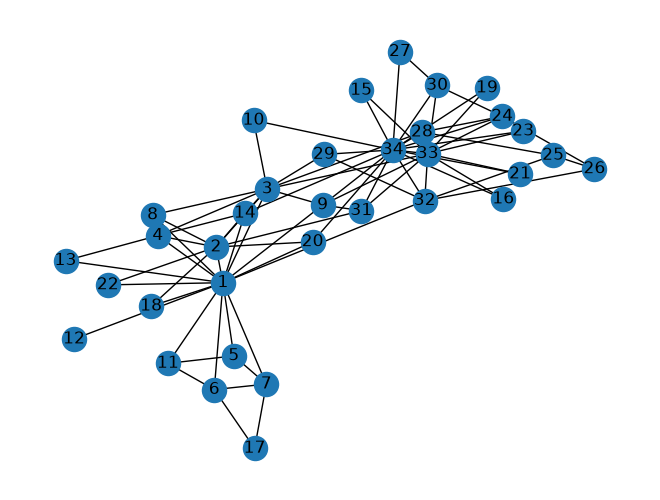

In [7]:
# LEAVE THIS CODE AS-IS

pos = nx.spring_layout(karate_club)
nx.draw(karate_club, pos=pos, with_labels=True)

## 1.1 Node and edge styles

The method `nx.draw` we used above is nice for quick visualizations, but for finer control over node and edge drawing, we use another set of lower-level methods that draw components individually:
- [`nx.draw_network_nodes`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx_nodes.html) — for drawing **nodes** only
- [`nx.draw_network_labels`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx_labels.html) — for drawing **node labels** only
- [`nx.draw_network_edges`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx_edges.html) — for drawing **edges** only
- [`nx.draw_networkx_edge_labels`](https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx_edge_labels.html) — for drawing **edge labels** only

Using a combination of these functions, we can choose which elements of the network to draw and with what styles (they expose a more complete set of style options than `draw`).

Your task is to use these functions and (by looking at the documentation) find a way to draw the Karate Club graph with:
- Nodes as green squares with white labels
- Edges in any color with a 50% transparency
- Nodes arranged in a circular layout
- Sizes of nodes, edges, and labels appropriate to make the network readable

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

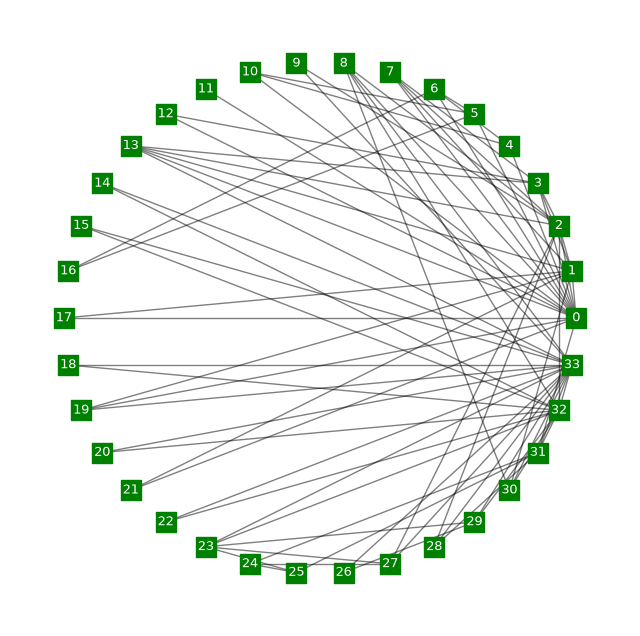

In [18]:
G = nx.karate_club_graph()
pos = nx.circular_layout(G)
plt.figure(figsize=(8, 8))

nx.draw_networkx_edges(G, pos, alpha=0.5, width=1)

nx.draw_networkx_nodes(G, pos, node_shape="s", node_color="green", node_size=200)

nx.draw_networkx_labels(G, pos, font_color="white", font_size=9)

plt.axis("off")
plt.show()

This was just an example — now let's make a more meaningful drawing.

In particular, we often want to draw nodes and edges with different styles, where the style conveys some meaningful information about these element (e.g. node classes or edge widths). Many of the parameters (e.g. color, size) in the drawing functions accept lists rather than single values precisely for this purpose, allowing you to have a different style for each node/edge/label.

NetworkX has many functions for calculating common node/edge attributes. Let's try to draw the network with the node and edge [betweenness centrality](https://en.wikipedia.org/wiki/Betweenness_centrality). We provide you the functions to do this in the following cell, where the results are dictionaries with node labels as keys.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [19]:
# LEAVE THIS CODE AS-IS

kc_node_betweenness = nx.betweenness_centrality(karate_club)
kc_edge_betweenness = nx.edge_betweenness_centrality(karate_club)

<font size="+1" color="red">Replace this cell with your code to draw the graph with node color and edge width proportional to node and edge betweenness, respectively.</font>

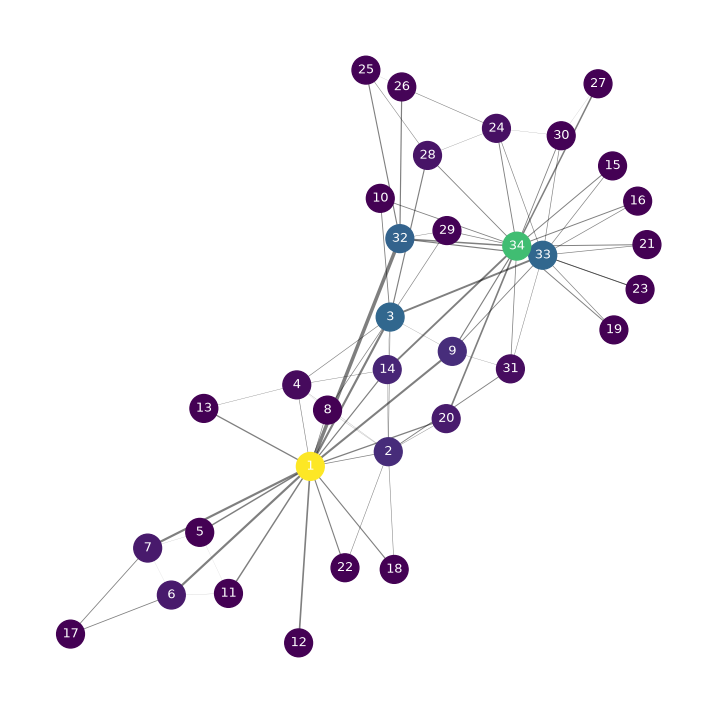

In [24]:
pos = nx.spring_layout(karate_club)

# Llistes en el mateix ordre que nodes i arestes
node_values = [kc_node_betweenness[n] for n in karate_club.nodes()]
edge_values = [kc_edge_betweenness[e] for e in karate_club.edges()]

# Gruix proporcional (multipliquem per un factor perquè es vegi)
edge_widths = [v * 20 for v in edge_values]

plt.figure(figsize=(9, 9))

nx.draw_networkx_edges(karate_club, pos, width=edge_widths, alpha=0.5)

nx.draw_networkx_nodes(
    karate_club, pos,
    node_color=node_values,   # llista de números -> es converteix en colors
    cmap=plt.cm.viridis,      # mapa de colors
    node_size=400,
)

nx.draw_networkx_labels(karate_club, pos, font_size=9, font_color="white")

plt.axis("off")
plt.show()

<font size="+1" color="red">Replace this cell with what "closeness centrality" and "betweenness centrality" mean, in your own words.</font>

El closeness centrality és la inversa del sumatòri de la distància entre el node i la resta de nodes. I el betweenness centrality és la quantitat de camins més curts que passen per aquell node des de la resta de nodes.

## 1.2 Drawing communities

We have already mentioned that the social network that the Karate Club graph describes eventually split into two factions. Let's draw the graph with nodes styles according to their factions. The faction membership is contained in the `karate-factions.csv` file that you can find on the course GitHub repo — if you haven't clones the repository, download the file now. Open the file with a text editor to check its contents.

For this exercise:
- `open` the CSV file
- Read the file's contents, e.g. line-by-line using `for line in file : ...`
- Extract the node ID and faction label from each line
- Assign the label to a new attribute named "faction" of the nodes in `karate_club`

*Tip: The easiest way to do the last step is to access the nodes as a dictionary-like object via `karate_club.nodes`.*

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to read the factions and store them as node attributes, as described above.</font>

In [30]:
with open("data/karate-club/karate-factions.csv") as file:
    next(file)                          # salta la capçalera
    for line in file:
        node_id, faction = line.split() # separa per espais/tabuladors
        karate_club.nodes[int(node_id)]["faction"] = faction

In [31]:
# LEAVE THIS CODE AS-IS

print(karate_club.nodes(data='faction'))

[(1, 'A'), (2, 'A'), (3, 'A'), (4, 'A'), (5, 'A'), (6, 'A'), (7, 'A'), (8, 'A'), (9, 'A'), (10, 'B'), (11, 'A'), (12, 'A'), (13, 'A'), (14, 'A'), (15, 'B'), (16, 'B'), (17, 'A'), (18, 'A'), (19, 'B'), (20, 'A'), (21, 'B'), (22, 'A'), (23, 'B'), (24, 'B'), (25, 'B'), (26, 'B'), (27, 'B'), (28, 'B'), (29, 'B'), (30, 'B'), (31, 'B'), (32, 'B'), (33, 'B'), (34, 'B')]


Now, use this information to draw the graph with nodes styled by their faction. Use the drawing functions already discussed.

The layout and styles for other elements can be whatever you like, as long as the graph is readable.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to draw the Karate Club graph with node styles (at least color and shape) based on factions.</font>

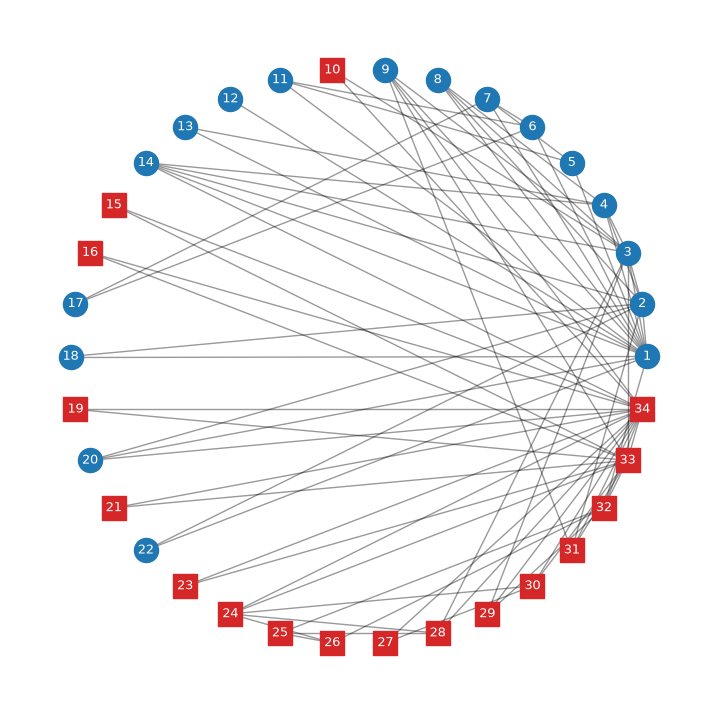

In [33]:
pos = nx.circular_layout(karate_club)

# Separem els nodes per facció
nodes_A = [n for n, f in karate_club.nodes(data="faction") if f == "A"]
nodes_B = [n for n, f in karate_club.nodes(data="faction") if f == "B"]

plt.figure(figsize=(9, 9))

# 1. Arestes (primer, perquè quedin per sota)
nx.draw_networkx_edges(karate_club, pos, alpha=0.4)

# 2. Nodes de la facció A: cercles blaus
nx.draw_networkx_nodes(karate_club, pos, nodelist=nodes_A,
                       node_color="tab:blue", node_shape="o", node_size=300)

# 3. Nodes de la facció B: quadrats vermells
nx.draw_networkx_nodes(karate_club, pos, nodelist=nodes_B,
                       node_color="tab:red", node_shape="s", node_size=300)

# 4. Etiquetes
nx.draw_networkx_labels(karate_club, pos, font_size=9, font_color="white")

plt.axis("off")
plt.show()

## 1.3 Degree distribution

Apart from graph visualization and graph algorithms, `networkx` provides us with many convenience functions for studying the **structure of the network**. 

For example, given a network `G`, we can get the **degree** of all nodes via `G.degree()` or the neighbors of node `x` via `G.neighbors(x)`.

For this exercise, extract the **degree distribution** of the Karate Club graph, and plot it as a **histogram**. A few notes:
- Make sure the bins of the histogram represent the number of nodes *with each discrete degree* (i.e., the first bin value is the number of nodes with degree 1, the second is the number of nodes with degree 2, etc.)
- Include proper labels for the x and y axes, and an appropriate title

You can use either the Pyplot `hist` or `bar` functions, as you prefer.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to plot the degree distribution based on the criteria described above.</font>

# 2. The Flavors bi-partite graph

Now we move on to analyzing the ***Flavors* network**. The dataset, prepared by [Ling Cheng in 2016](https://github.com/lingcheng99/Flavor-Network), contains three files:

* `ingredients.tsv` — information about culinary ingredients
* `compounds.tsv` — information about flavour compounds
* `ingredient-compound.tsv` — flavour compounds present in each culinary ingredient

You can find this dataset in the `practicum/data/flavors-network` folder in the course GitHub repo.

## 2.0. Examine your input files

Before you begin, we highly recommend you to:

1. Make sure you have the input files locally available on your computer
2. Open them in a spreadsheet and look at them

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

## 2.1. Read the data into Pandas DataFrames


For the analysis in this section, we will use the [**Pandas**](https://pandas.pydata.org) Python package. Pandas is a powerful set of tools for representing and analyzing data as *tables* (also known as *DataFrames*), i.e. structured in rows and columns.

Since some of you might not have come across this tool yet, we will guide you through the process, but *if you're having trouble following along we **recommend** the visual [*Intro to pandas*](https://pandas.pydata.org/docs/getting_started/index.html#intro-to-pandas)*. 

There are other [tutorials](https://pandas.pydata.org/docs/getting_started/index.html#tutorials) in the official documentation, such as [*10 Minutes to pandas*](https://pandas.pydata.org/docs/user_guide/10min.html) or the [syntax cheat sheet](https://pandas.pydata.org/Pandas_Cheat_Sheet.pdf), which you mind find useful.

---

In the following cells, we load the read the ingredient-compound relationships into three `DataFrame`s. Take a second to inspect the functions we use.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [14]:
# EDIT THIS CODE if needed to point to your file (as you will include it in the submission zip)

INPUT_INGR_FILENAME = "data/flavors-network/ingredients.tsv"
INPUT_COMP_FILENAME = "data/flavors-network/compounds.tsv"
INPUT_INGR_COMP_FILENAME = "data/flavors-network/ingredient-compound.tsv"

In [15]:
# LEAVE THIS CODE AS-IS

import pandas as pd

ingredients = pd.read_csv(INPUT_INGR_FILENAME, sep="\t")
display(ingredients.head(3))

compounds = pd.read_csv(INPUT_COMP_FILENAME, sep="\t")
display(compounds.head(3))

ingr_comp = pd.read_csv(INPUT_INGR_COMP_FILENAME, sep="\t")
display(ingr_comp.head(3))

,ingredient_id,ingredient_name,ingredient_category
0,0,magnolia_tripetala,flower
1,1,calyptranthes_parriculata,plant
2,2,chamaecyparis_pisifera_oil,plant derivative


,compound_id,compound_name,compound_code
0,0,jasmone,488-10-8
1,1,5-methylhexanoic_acid,628-46-6
2,2,l-glutamine,56-85-9


,ingredient_id,compound_id
0,1392,906
1,1259,861
2,1079,673


## 2.2. Create the flavors bipartite network


Create a new dataframe named `flavors` that stores ingredient-compound relationships, by joining `ingredients` and `compounds`.

*Tips*:

* To [`join`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html) DataFrames `A` and `B` using a column *X*, use `A.set_index('X').join(B.set_index('X'), how='inner')`
* You will need to do two joins to solve this, using `ingr_comp` as intermediary.
* Most functions on DataFrames return new DataFrames, so keep track of your variable assignments!

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to create the `flavors` dataframe and show its first 10 rows.</font>

From the `flavors` DataFrame, extract a new DataFrame by dropping the "compound_code" and "ingredient_category" columns, sorting by "ingredient_name" then by "compound_name", and resetting the index. This will be the DataFrame we use to create the Flavors bipartite network.

*Some tips for manipulating DataFrames:*
* To [drop](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.drop.html) column *X* from DataFrame `A`, you can do: `A.drop(columns=['X'])`
* To [sort](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.sort_values.html) DataFrame `A` by column *X*, you can do: `A.sort_values(['X', 'Y'])` (for this exercise, you will need to do a double sort — check the documentation)
* To [reset the index](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.reset_index.html) of a DataFrame `A`, you can do: `A.reset_index(drop=True)`
* To change the order of DataFrame columns, simply index the DataFrame with a list of columns in the order you'd like, e.g. `A[['col2', 'col1']]`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to modify the `flavors` dataframe as explained above, and show its first 10 rows.</font>

Write this DataFrame to a file named "flavors.tsv", which should be a tab-separated file containing the two fields `ingredient_name` and `compound_name`. 

*Hint: there is a `pandas` function for this.*

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to save `flavors` into a tab-separated file.</font>

## 2.3. Visualize a small part of this graph

### 2.3.1 Examine the file you generated
Open the ``flavors.tsv`` file in a spreadsheet program to make sure you generated it correctly; it should have exactly 2 tab-separated columns.

### 2.3.2 Use this file to create a NetworkX Graph

There are at least two ways of doing this:
- Using `nx.parse_edgelist` on an open CSV file, passing it an appropriate delimiter and data types (see documentation)
- Going through the lines of the CSV file with a `reader` and adding edges manually, via `G.add_edge` and similar

Both are valid, and you can use either. The result must be a `nx.Graph` instance. Assign it to a variable named `flavors_graph`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to create the `flavors_graph`.</font>

The code below performs some basic tests to make sure the network was imported successfully from the CSV file.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

In [20]:
# LEAVE THIS CODE AS-IS

print(f"Number of nodes: {flavors_graph.number_of_nodes()}")
print(f"Number of edges: {flavors_graph.number_of_edges()}")
print(f"Number of connected components: {nx.number_connected_components(flavors_graph)}")

Number of nodes: 2631
Number of edges: 36781
Number of connected components: 22


To make the visualizations more inforamtive, let's add ingredient category information as a node attribute to our graph.

Node and edge data can be added in a couple of ways, for example for a graph `G`:
- `G.nodes[x]` to access the attribute dictionary of node `x` of graph `G`, as we did earlier for the Karate Club factions
- `nx.set_node_attributes(G, values=node_to_attribute_dict, name='attribute')` to set the attribute named "attribute" to the corresponding values in `node_to_attribute_dict`, keyed by node labels.

*Hint: use one of the DataFrames we already defined.*

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to add the igredient type to each ingredient node in the `flavors_graph`.</font>

In [22]:
# LEAVE THIS CODE AS-IS

for node in ['caffeine', 'green_tea', 'dill'] :
    print(f"{node:<10}: {flavors_graph.nodes[node]}")

caffeine  : {}
green_tea : {'category': 'plant derivative'}
dill      : {'category': 'herb'}


### 2.3.3 Draw the flavors graph of diacetyl

Your goal is to visualize the flavors graph, but since it is quite large we will first extract a subgraph.

1. Find the node corresponding to the compound [***diacetyl***](https://en.wikipedia.org/wiki/Diacetyl) and all the nodes connected to it at distance 1 or 2. *Hint: use the `G.neighbors` method for this.*
2. Extract the subgraph that includes these nodes. You can define a new graph using `nx.subgraph`.
3. Assign this to a variable named `flavors_graph_diacetyl`.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to extract `flavors_graph_diacetyl`.</font>

In [24]:
# LEAVE THIS CODE AS-IS

print(f"Number of nodes: {flavors_graph_cinnamon.number_of_nodes()}")
print(f"Number of edges: {flavors_graph_cinnamon.number_of_edges()}")
print(f"Degree of diacetyl: {flavors_graph_cinnamon.degree('diacetyl')}")

Number of nodes: 885
Number of edges: 13480
Degree of diacetyl: 112


Now, visualize this subgraph.

Style the network such that:
- Ingredient nodes have a color that depends on their category, using any color except gray. Set gray to be the default node color so that compound nodes remain gray.
- Highlight the focal node ("diacetyl") by making it larger, changing its shape, and adding a different border color.

As we draw larger networks, the goal is to appreciate the overall organization and major clusters. Make sure your drawing is **readable** and **informative**. 
Some tips for this:
- You might want to reduce node and edge sizes and/or transparency to make sure all elements are visible.
- If there are too many nodes, drawing (all) node labels might not be a good idea.
- Play around with the parameters of `nx.spring_layout` (especially `k` and `iterations`) to get a good visualization. (Read the documentation for a description of each parameter.)
- The `networkx` draw functions use Matplotlib behind the scenes, and you can access e.g. the current figure via `plt.gcf()`. From there, you can change figure sizes, axes borders, etc.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code to draw the subgraph you just extracted.</font>

### 2.3.4 Compounds in common

*coffee* and *tea* are beloved beberages for their rich, complex flavors, which come from various alkaloid compounds. How many alkaloid compounds do coffee and tea have in common? Based solely on their names, how many of them do you think contribute to their bitterness?


---
*Quick chemestry lesson: you can identify some alkaloid compounds by name, since they tend to finish with "pyrrole", "pyrazine", "quinoline", "Theobromine"*

---

To answer this question, extract the nodes *coffee*, *tea*, and all their compounds in common as a graph.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+1" color="red">Replace this cell with your code for generating the subgraph.</font>

<font size="+1" color="red">Replace this cell with a brief commentary indicating how many compounds they have in common and how many of them seem to contain pyrazine (based on their names). List a couple of those alkaloid-containing compounds.</font>

<font size="+1" color="red">Replace this cell with a brief explanation on why, in this case, the nodes with degree 2 correspond the compounds in common.</font>

Remember to save this notebook and compresss it before uploading.

<font size="-1" color="gray">(Remove this cell when delivering.)</font>

<font size="+2" color="#003300">I hereby declare that, except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>
